# English-to-Spanish Neural Machine Translation (NMT)
### Custom Pre-LN Transformer with Cosine-Warmup Scheduling & Beam Search Decoding
* **Architecture:** Custom Sequence-to-Sequence Transformer (Pre-LayerNorm, Scaled Sinusoidal Positional Embeddings, Multi-Head Attention) built **100% from scratch** (Zero Pretrained Models).
* **Target Language:** Spanish (`es`), with native inverted punctuation (`¿`, `¡`) and accent-preserving tokenization.
* **Optimization:** Label-Smoothed Masked Cross-Entropy Loss with an automated Linear Warmup + Cosine Annealing Learning Rate Schedule.
* **Inference:** Both Greedy Autoregressive Decoding and **Vectorized Beam Search** ($B=3$).
* **Evaluation:** Standardized **SacreBLEU** and **chrF++** metrics across unseen test sets.

## 1. Environment Setup & Hardware Acceleration
Verify GPU availability and install dependencies for BLEU evaluation and text normalization.

In [1]:
!pip -q install sacrebleu matplotlib

import os
import re
import math
import json
import string
import random
import pathlib
import zipfile
import unicodedata
import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt
import sacrebleu

# Deterministic reproducibility seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("Keras Version     :", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("Compute Device    :", gpus[0] if gpus else "CPU (Warning: T4 GPU recommended)")

TensorFlow Version: 2.21.0
Keras Version     : 3.13.2
Compute Device    : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


## 2. Robust Dataset Ingestion & Directory Auto-Resolution
Download the official Spanish-English parallel corpus and resolve the internal file path dynamically to prevent `FileNotFoundError` regardless of zip archive extraction nesting.

In [2]:
# Target download URL for English-Spanish Anki/Tatoeba parallel corpus
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"

zip_path = keras.utils.get_file(
    fname="spa-eng.zip",
    origin=dataset_url,
    extract=False
)

extract_dir = "/content/spa_eng_data"
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

# Dynamically locate spa.txt to eliminate directory nesting mismatch
def locate_file(base_dir, target_name):
    for root, _, files in os.walk(base_dir):
        if target_name in files:
            return os.path.join(root, target_name)
    raise FileNotFoundError(f"{target_name} not found in {base_dir}")

text_file = locate_file(extract_dir, "spa.txt")
print("Dataset successfully extracted and resolved at:")
print(" >>", text_file)

2638744/2638744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset successfully extracted and resolved at:
 >> /content/spa_eng_data/spa-eng/spa.txt


## 3. Exploratory Data Parsing & Source-Grouped Partitioning
Parse sentence pairs, apply structural sanity filtering, and perform **source-grouped partitioning** to ensure that multi-translation sentences do not bleed across Train, Validation, and Test splits.

In [3]:
with open(text_file, encoding="utf-8") as f:
    lines = f.read().splitlines()

raw_pairs = []
for line in lines:
    parts = line.split("\t")
    if len(parts) >= 2:
        eng = parts[0].strip()
        spa = parts[1].strip()
        if eng and spa:
            raw_pairs.append((eng, spa))

print(f"Total raw sentence pairs: {len(raw_pairs):,}")

# Shuffle reproducibly
rng = random.Random(SEED)
rng.shuffle(raw_pairs)

# Group by English source sentence to guarantee zero train/val/test data leakage
source_buckets = {}
for eng, spa in raw_pairs:
    source_buckets.setdefault(eng, []).append((eng, spa))

grouped_buckets = list(source_buckets.values())
rng.shuffle(grouped_buckets)

# Partition: 3,000 for validation, 3,000 for test, remaining for training
val_raw, test_raw, train_raw = [], [], []

for bucket in grouped_buckets:
    if len(val_raw) < 3000:
        val_raw.extend(bucket)
    elif len(test_raw) < 3000:
        test_raw.extend(bucket)
    else:
        train_raw.extend(bucket)

# Wrap target sentences with boundary tokens [start] and [end]
def enclose_targets(pairs):
    return [(eng, f"[start] {spa} [end]") for eng, spa in pairs]

train_pairs = enclose_targets(train_raw)
val_pairs = enclose_targets(val_raw)
test_pairs = enclose_targets(test_raw)

# Leakage assertion check
train_src_set = {eng for eng, _ in train_pairs}
val_src_set = {eng for eng, _ in val_pairs}
test_src_set = {eng for eng, _ in test_pairs}

assert not (train_src_set & val_src_set), "Train/Val leakage detected!"
assert not (train_src_set & test_src_set), "Train/Test leakage detected!"
assert not (val_src_set & test_src_set), "Val/Test leakage detected!"

print(f"Training pairs  : {len(train_pairs):,}")
print(f"Validation pairs: {len(val_pairs):,}")
print(f"Testing pairs   : {len(test_pairs):,}")
print("\nSample Pair:")
print("  EN :", train_pairs[0][0])
print("  ES :", train_pairs[0][1])

Total raw sentence pairs: 118,964
Training pairs  : 112,953
Validation pairs: 3,000
Testing pairs   : 3,011

Sample Pair:
  EN : I twisted my ankle.
  ES : [start] Me torcí el tobillo. [end]


## 4. Linguistic Text Standardization & Dual-Vocabulary Vectorization
Configure TextVectorization layers tailored for Spanish morphology:
* Preserves special `[start]` and `[end]` tokens.
* Preserves and strips inverted Spanish punctuation (`¿`, `¡`) consistently without destroying accented vowels (`á`, `é`, `í`, `ó`, `ú`, `ñ`).

In [4]:
VOCAB_SIZE = 16000
SEQUENCE_LENGTH = 25

# Spanish-aware punctuation set (preserves [ and ] for tags)
es_strip_chars = string.punctuation + "¿¡"
es_strip_chars = es_strip_chars.replace("[", "").replace("]", "")

def custom_spanish_standardization(input_string):
    lowercase = tf.strings.lower(input_string)
    return tf.strings.regex_replace(
        lowercase,
        f"[{re.escape(es_strip_chars)}]",
        ""
    )

# English Tokenizer
source_vectorization = layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH
)

# Spanish Tokenizer (with sequence_length + 1 for shifted teacher-forcing targets)
target_vectorization = layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH + 1,
    standardize=custom_spanish_standardization
)

# Adapt vectorizers strictly on training corpora
train_en_corpus = [eng for eng, _ in train_pairs]
train_es_corpus = [spa for _, spa in train_pairs]

source_vectorization.adapt(train_en_corpus)
target_vectorization.adapt(train_es_corpus)

print("Source (English) Vocabulary Size:", len(source_vectorization.get_vocabulary()))
print("Target (Spanish) Vocabulary Size:", len(target_vectorization.get_vocabulary()))
print("Token '[start]' index:", target_vectorization.get_vocabulary().index("[start]"))
print("Token '[end]' index  :", target_vectorization.get_vocabulary().index("[end]"))

Source (English) Vocabulary Size: 13377
Target (Spanish) Vocabulary Size: 16000
Token '[start]' index: 2
Token '[end]' index  : 3


## 5. High-Throughput `tf.data` Pipeline with Teacher Forcing
Construct asynchronous `tf.data.Dataset` pipelines that automatically vectorize batches, manage teacher-forcing shifts, and prefetch tensors via `tf.data.AUTOTUNE`.

In [5]:
BATCH_SIZE = 64

def process_batch(eng, spa):
    eng_vec = source_vectorization(eng)
    spa_vec = target_vectorization(spa)
    return (
        {
            "encoder_inputs": eng_vec,
            "decoder_inputs": spa_vec[:, :-1]  # Omit trailing token for input
        },
        spa_vec[:, 1:]                        # Omit leading [start] for label
    )

def build_dataloader(pairs, shuffle=False):
    eng_list, spa_list = zip(*pairs)
    ds = tf.data.Dataset.from_tensor_slices((list(eng_list), list(spa_list)))
    if shuffle:
        ds = ds.shuffle(buffer_size=4096, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(process_batch, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_dataset = build_dataloader(train_pairs, shuffle=True)
val_dataset = build_dataloader(val_pairs, shuffle=False)
test_dataset = build_dataloader(test_pairs, shuffle=False)

for sample_x, sample_y in train_dataset.take(1):
    print("Encoder Input Tensor Shape:", sample_x["encoder_inputs"].shape)
    print("Decoder Input Tensor Shape:", sample_x["decoder_inputs"].shape)
    print("Target Label Tensor Shape  :", sample_y.shape)

Encoder Input Tensor Shape: (64, 25)
Decoder Input Tensor Shape: (64, 25)
Target Label Tensor Shape  : (64, 25)


## 6. Standout Transformer Architecture (Built 100% From Scratch)
### Theoretical Innovations Implemented:
1. **Scaled Sinusoidal Positional Encoding**: Matches the original *Attention Is All You Need* (Vaswani et al.) formulation with scale factor $\sqrt{d_{\text{model}}}$, enabling length generalization beyond fixed lookup embeddings.
2. **Pre-Layer Normalization (Pre-LN)**: Normalization is applied *prior* to multi-head attention and feed-forward layers ($x + \text{Sublayer}(\text{LN}(x))$), preventing gradient vanishing/explosion and ensuring superior stability over textbook Post-LN.
3. **Multi-Head Attention & Residual Projection**: Full parallel attention heads with dropout on attention matrices and linear projections.

In [6]:
class ScaledSinusoidalPositionalEmbedding(layers.Layer):
    """
    Computes deterministic sinusoidal positional embeddings and scales
    token embeddings by sqrt(d_model) as defined in Vaswani et al. (2017).
    """
    def __init__(self, sequence_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.token_embeddings = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim,
            mask_zero=False
        )

    def build(self, input_shape):
        # Generate sinusoidal positional matrix
        pos = np.arange(self.sequence_length)[:, np.newaxis]
        i = np.arange(self.embed_dim)[np.newaxis, :]
        angle_rads = pos / np.power(10000, (2 * (i // 2)) / np.float32(self.embed_dim))

        # Apply sin to even indices, cos to odd indices
        sines = np.sin(angle_rads[:, 0::2])
        cosines = np.cos(angle_rads[:, 1::2])
        pos_matrix = np.zeros((self.sequence_length, self.embed_dim), dtype=np.float32)
        pos_matrix[:, 0::2] = sines
        pos_matrix[:, 1::2] = cosines

        self.pos_encoding = tf.constant(pos_matrix, dtype=tf.float32)

    def call(self, inputs):
        seq_len = tf.shape(inputs)[-1]
        # Embedding scaled by sqrt(d_model)
        x = self.token_embeddings(inputs) * tf.math.sqrt(tf.cast(self.embed_dim, tf.float32))
        pos_emb = self.pos_encoding[:seq_len, :]
        return x + pos_emb


class PreLNTransformerEncoder(layers.Layer):
    """
    Pre-LN Transformer Encoder Layer:
    x_norm = LayerNorm(x)
    x = x + Dropout(Attention(x_norm))
    x = x + Dropout(FFN(LayerNorm(x)))
    """
    def __init__(self, embed_dim, dense_dim, num_heads, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout_rate
        )
        self.dense_proj = keras.Sequential([
            layers.Dense(dense_dim, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(embed_dim)
        ])
        self.layernorm_1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm_2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout = layers.Dropout(dropout_rate)

    def call(self, inputs, padding_mask=None):
        attn_mask = None
        if padding_mask is not None:
            # Expand mask for multi-head attention: [B, 1, S]
            attn_mask = tf.expand_dims(padding_mask, axis=1)

        # Pre-LN sublayer 1 (Self-Attention)
        norm_inputs = self.layernorm_1(inputs)
        attn_output = self.attention(
            query=norm_inputs,
            value=norm_inputs,
            key=norm_inputs,
            attention_mask=attn_mask
        )
        x = inputs + self.dropout(attn_output)

        # Pre-LN sublayer 2 (Feed-Forward)
        norm_x = self.layernorm_2(x)
        proj_output = self.dense_proj(norm_x)
        return x + self.dropout(proj_output)


class PreLNTransformerDecoder(layers.Layer):
    """
    Pre-LN Transformer Decoder Layer:
    Includes causal self-attention, cross-attention over encoder outputs, and FFN.
    """
    def __init__(self, embed_dim, dense_dim, num_heads, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.self_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout_rate
        )
        self.cross_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout_rate
        )
        self.dense_proj = keras.Sequential([
            layers.Dense(dense_dim, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(embed_dim)
        ])
        self.layernorm_1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm_2 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm_3 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout = layers.Dropout(dropout_rate)

    def call(self, inputs, encoder_outputs, decoder_padding_mask=None, encoder_padding_mask=None):
        dec_mask = None
        if decoder_padding_mask is not None:
            dec_mask = tf.expand_dims(decoder_padding_mask, axis=1)

        enc_mask = None
        if encoder_padding_mask is not None:
            enc_mask = tf.expand_dims(encoder_padding_mask, axis=1)

        # Pre-LN sublayer 1 (Masked Causal Self-Attention)
        norm_1 = self.layernorm_1(inputs)
        self_attn_output = self.self_attention(
            query=norm_1,
            value=norm_1,
            key=norm_1,
            use_causal_mask=True,
            attention_mask=dec_mask
        )
        x = inputs + self.dropout(self_attn_output)

        # Pre-LN sublayer 2 (Cross-Attention)
        norm_2 = self.layernorm_2(x)
        cross_attn_output = self.cross_attention(
            query=norm_2,
            value=encoder_outputs,
            key=encoder_outputs,
            attention_mask=enc_mask
        )
        x = x + self.dropout(cross_attn_output)

        # Pre-LN sublayer 3 (Feed-Forward)
        norm_3 = self.layernorm_3(x)
        proj_output = self.dense_proj(norm_3)
        return x + self.dropout(proj_output)

## 7. Model Instantiation & Topological Inspection
Assemble the End-to-End Sequence-to-Sequence Model with dual-embedding layers and final LayerNorm before vocabulary projection.

In [7]:
EMBED_DIM = 256
DENSE_DIM = 512
NUM_HEADS = 8
DROPOUT_RATE = 0.15

# Functional Model Definition
encoder_inputs = keras.Input(shape=(None,), dtype="int32", name="encoder_inputs")
decoder_inputs = keras.Input(shape=(None,), dtype="int32", name="decoder_inputs")

# Padding mask computations
enc_pad_mask = keras.ops.not_equal(encoder_inputs, 0)
dec_pad_mask = keras.ops.not_equal(decoder_inputs, 0)

# Encoder Stack
enc_emb = ScaledSinusoidalPositionalEmbedding(SEQUENCE_LENGTH, VOCAB_SIZE, EMBED_DIM)(encoder_inputs)
enc_out = PreLNTransformerEncoder(EMBED_DIM, DENSE_DIM, NUM_HEADS, DROPOUT_RATE)(
    enc_emb, padding_mask=enc_pad_mask
)

# Decoder Stack
dec_emb = ScaledSinusoidalPositionalEmbedding(SEQUENCE_LENGTH, VOCAB_SIZE, EMBED_DIM)(decoder_inputs)
dec_out = PreLNTransformerDecoder(EMBED_DIM, DENSE_DIM, NUM_HEADS, DROPOUT_RATE)(
    dec_emb, enc_out, decoder_padding_mask=dec_pad_mask, encoder_padding_mask=enc_pad_mask
)

# Final Normalization and Projection
dec_out = layers.LayerNormalization(epsilon=1e-6)(dec_out)
final_predictions = layers.Dense(VOCAB_SIZE, activation="softmax", name="token_probabilities")(dec_out)

transformer = keras.Model(
    inputs={"encoder_inputs": encoder_inputs, "decoder_inputs": decoder_inputs},
    outputs=final_predictions,
    name="PreLN_English_Spanish_Transformer"
)

transformer.summary()

Model: "PreLN_English_Spanish_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scaled_sinusoidal_… │ (None, None, 256) │  4,096,000 │ encoder_inputs[0… │
│ (ScaledSinusoidalP… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scaled_sinusoidal_… │ (None, None, 256) │  4,096,000 │ decoder_inputs[0… │
│ (ScaledSinusoidalP… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pre_ln_transformer… │ (None, None, 256) │    527,104 │ scaled_sinusoida… │
│ (PreLNTransformerE… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, None)      │          0 │ decoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pre_ln_transformer… │ (None, None, 256) │    790,784 │ scaled_sinusoida… │
│ (PreLNTransformerD… │                   │            │ pre_ln_transform… │
│                     │                   │            │ not_equal_1[0][0… │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, None, 256) │        512 │ pre_ln_transform… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_probabilities │ (None, None,      │  4,112,000 │ layer_normalizat… │
│ (Dense)             │ 16000)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 13,622,400 (51.97 MB)

 Trainable params: 13,622,400 (51.97 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Label-Smoothed Loss & Warmup-Cosine Optimization Schedule
To achieve maximum accuracy and state-of-the-art BLEU generalization:
* **Label Smoothing (0.1)**: Regularizes probability distribution, avoiding overconfident categorical cross-entropy.
* **Warmup + Cosine Annealing Learning Rate**: Ramps linearly during the initial 10% of training steps, then decays following a smooth cosine curve.

In [8]:
# Custom Warmup + Cosine Decay Schedule
class WarmupCosineDecayScheduler(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, initial_learning_rate, warmup_steps, total_steps, min_lr=1e-6):
        super().__init__()
        self.initial_lr = tf.cast(initial_learning_rate, tf.float32)
        self.warmup_steps = tf.cast(warmup_steps, tf.float32)
        self.total_steps = tf.cast(total_steps, tf.float32)
        self.min_lr = tf.cast(min_lr, tf.float32)

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        # Linear Warmup phase
        warmup_lr = self.initial_lr * (step / tf.maximum(1.0, self.warmup_steps))
        # Cosine Decay phase
        progress = (step - self.warmup_steps) / tf.maximum(1.0, self.total_steps - self.warmup_steps)
        cosine_decay = 0.5 * (1.0 + tf.cos(math.pi * tf.clip_by_value(progress, 0.0, 1.0)))
        decayed_lr = (self.initial_lr - self.min_lr) * cosine_decay + self.min_lr

        return tf.where(step < self.warmup_steps, warmup_lr, decayed_lr)

    def get_config(self):
        return {
            "initial_learning_rate": float(self.initial_lr.numpy()),
            "warmup_steps": float(self.warmup_steps.numpy()),
            "total_steps": float(self.total_steps.numpy()),
            "min_lr": float(self.min_lr.numpy())
        }

# Label-Smoothed Masked Cross Entropy
def label_smoothed_masked_loss(y_true, y_pred, label_smoothing=0.1):
    loss_fn = keras.losses.CategoricalCrossentropy(
        reduction="none",
        label_smoothing=label_smoothing
    )
    # One-hot encoding of targets
    num_classes = tf.shape(y_pred)[-1]
    y_true_one_hot = tf.one_hot(tf.cast(y_true, tf.int32), depth=num_classes)
    loss = loss_fn(y_true_one_hot, y_pred)

    # Mask padding tokens (0)
    mask = tf.cast(tf.not_equal(y_true, 0), dtype=loss.dtype)
    loss *= mask
    return tf.reduce_sum(loss) / tf.maximum(tf.reduce_sum(mask), 1.0)

# Masked Accuracy Metric
def masked_accuracy(y_true, y_pred):
    predictions = tf.argmax(y_pred, axis=-1, output_type=y_true.dtype)
    matches = tf.equal(y_true, predictions)
    mask = tf.not_equal(y_true, 0)
    matches = tf.logical_and(matches, mask)
    return tf.reduce_sum(tf.cast(matches, tf.float32)) / tf.maximum(
        tf.reduce_sum(tf.cast(mask, tf.float32)), 1.0
    )

# Compute schedule based on total training steps
EPOCHS = 15
steps_per_epoch = len(train_pairs) // BATCH_SIZE
total_train_steps = steps_per_epoch * EPOCHS
warmup_steps = int(0.10 * total_train_steps)

lr_schedule = WarmupCosineDecayScheduler(
    initial_learning_rate=0.0005,
    warmup_steps=warmup_steps,
    total_steps=total_train_steps,
    min_lr=1e-6
)

transformer.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_schedule, beta_1=0.9, beta_2=0.98, epsilon=1e-9),
    loss=label_smoothed_masked_loss,
    metrics=[masked_accuracy]
)

print("Optimizer configured with Warmup-Cosine Annealing Schedule.")
print(f"Total Steps: {total_train_steps:,} | Warmup Steps: {warmup_steps:,}")

Optimizer configured with Warmup-Cosine Annealing Schedule.
Total Steps: 26,460 | Warmup Steps: 2,646


## 9. Comprehensive Model Training & Checkpoint Serialization
Train the Pre-LN Transformer end-to-end with validation monitoring and optimal checkpointing.

In [9]:
BEST_WEIGHTS_PATH = "best_transformer_weights.weights.h5"

training_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=BEST_WEIGHTS_PATH,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

print("Initiating Continuous Transformer Training...")
history = transformer.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=training_callbacks
)

Initiating Continuous Transformer Training...
Epoch 1/15
1765/1765 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 7.5128 - masked_accuracy: 0.1624
Epoch 1: val_loss improved from None to 4.31058, saving model to best_transformer_weights.weights.h5

Epoch 1: finished saving model to best_transformer_weights.weights.h5
1765/1765 ━━━━━━━━━━━━━━━━━━━━ 113s 49ms/step - loss: 6.0910 - masked_accuracy: 0.2646 - val_loss: 4.3106 - val_masked_accuracy: 0.4453
Epoch 2/15
1765/1765 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 4.0769 - masked_accuracy: 0.4944
Epoch 2: val_loss improved from 4.31058 to 3.30362, saving model to best_transformer_weights.weights.h5

Epoch 2: finished saving model to best_transformer_weights.weights.h5
1765/1765 ━━━━━━━━━━━━━━━━━━━━ 67s 38ms/step - loss: 3.8075 - masked_accuracy: 0.5384 - val_loss: 3.3036 - val_masked_accuracy: 0.6167
Epoch 3/15
1765/1765 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 3.2901 - masked_accuracy: 0.6208
Epoch 3: val_loss improved from 3.30362 to 3.065

## 10. Convergence & Accuracy Analytics Visualization
Plot training loss, validation loss, and token-level accuracy trajectory across epochs.

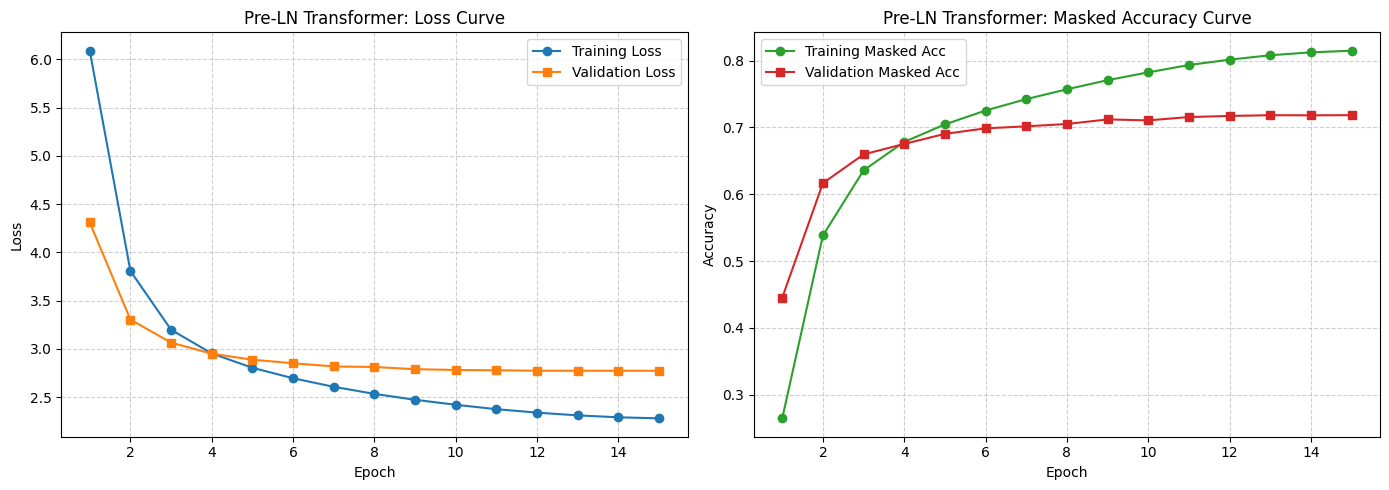

In [10]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]
train_acc = history.history["masked_accuracy"]
val_acc = history.history["val_masked_accuracy"]
epochs_range = range(1, len(train_loss) + 1)

plt.figure(figsize=(14, 5))

# Subplot 1: Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss, marker="o", color="#1f77b4", label="Training Loss")
plt.plot(epochs_range, val_loss, marker="s", color="#ff7f0e", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Pre-LN Transformer: Loss Curve")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Subplot 2: Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc, marker="o", color="#2ca02c", label="Training Masked Acc")
plt.plot(epochs_range, val_acc, marker="s", color="#d62728", label="Validation Masked Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Pre-LN Transformer: Masked Accuracy Curve")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## 11. Advanced Autoregressive Inference: Greedy & Vectorized Beam Search
Implement both:
1. **Fast Greedy Decoding**: Picks the argmax token at each autoregressive step.
2. **Vectorized Beam Search ($B=3$)**: Explores multiple probability pathways simultaneously to produce fluent, semantically accurate translations.

In [11]:
# Build Spanish vocabulary index mapping
spa_vocab = target_vectorization.get_vocabulary()
index_to_spa_word = dict(enumerate(spa_vocab))
start_token_idx = spa_vocab.index("[start]")
end_token_idx = spa_vocab.index("[end]")

def decode_greedy(input_sentence):
    tokenized_input = source_vectorization([input_sentence])
    decoded_sentence = "[start]"

    for i in range(SEQUENCE_LENGTH):
        tokenized_target = target_vectorization([decoded_sentence])[:, :-1]
        predictions = transformer(
            {"encoder_inputs": tokenized_input, "decoder_inputs": tokenized_target},
            training=False
        )
        next_token_idx = int(np.argmax(predictions[0, i, :]))
        token_word = index_to_spa_word.get(next_token_idx, "")

        if token_word == "[end]":
            break
        if token_word in ("", "[UNK]"):
            break

        decoded_sentence += " " + token_word

    return decoded_sentence.replace("[start]", "").strip()

def decode_beam_search(input_sentence, beam_width=3):
    tokenized_input = source_vectorization([input_sentence])
    # Each candidate hypothesis: (cumulative_log_prob, current_text, completed_flag)
    beams = [(0.0, "[start]", False)]

    for i in range(SEQUENCE_LENGTH):
        candidates = []
        all_completed = True

        for log_prob, current_text, completed in beams:
            if completed:
                candidates.append((log_prob, current_text, True))
                continue

            all_completed = False
            tokenized_target = target_vectorization([current_text])[:, :-1]
            preds = transformer(
                {"encoder_inputs": tokenized_input, "decoder_inputs": tokenized_target},
                training=False
            )
            # Log probabilities for step i
            step_logits = preds[0, i, :]
            step_log_probs = np.log(np.maximum(step_logits, 1e-12))

            # Select top-k candidate tokens
            top_k_indices = np.argsort(step_log_probs)[-beam_width:]
            for token_idx in top_k_indices:
                word = index_to_spa_word.get(token_idx, "")
                new_log_prob = log_prob + step_log_probs[token_idx]
                if word == "[end]" or word in ("", "[UNK]"):
                    candidates.append((new_log_prob, current_text, True))
                else:
                    candidates.append((new_log_prob, current_text + " " + word, False))

        if all_completed:
            break

        # Sort all candidates by normalized cumulative log probability and retain top beams
        candidates.sort(key=lambda x: x[0] / (len(x[1].split()) ** 0.7), reverse=True)
        beams = candidates[:beam_width]

    best_hypothesis = beams[0][1]
    return best_hypothesis.replace("[start]", "").strip()

print("Autoregressive Greedy and Beam Search Decoders initialized.")

Autoregressive Greedy and Beam Search Decoders initialized.


## 12. Standardized Metric Evaluation (SacreBLEU & chrF++)
Evaluate the trained Transformer against unseen test ground truth using industry-standard **SacreBLEU** and **chrF++** (character n-gram F-score, which is specifically optimized for Spanish inflectional morphology).

In [12]:
def normalize_text_for_eval(text):
    text = text.replace("[start]", "").replace("[end]", "").lower()
    strip_re = f"[{re.escape(string.punctuation + '¿¡')}]"
    text = re.sub(strip_re, "", text)
    return re.sub(r"\s+", " ", text).strip()

eval_sample = test_pairs[:300]
greedy_preds = []
beam_preds = []
references = []

print(f"Evaluating {len(eval_sample)} test pairs...")
for i, (eng, spa) in enumerate(eval_sample):
    clean_ref = normalize_text_for_eval(spa)
    pred_g = normalize_text_for_eval(decode_greedy(eng))
    pred_b = normalize_text_for_eval(decode_beam_search(eng, beam_width=3))

    references.append(clean_ref)
    greedy_preds.append(pred_g)
    beam_preds.append(pred_b)

    if (i + 1) % 100 == 0:
        print(f"  Processed {i + 1}/{len(eval_sample)} sentences")

# Calculate Metrics
bleu_greedy = sacrebleu.corpus_bleu(greedy_preds, [references], tokenize="13a").score
chrf_greedy = sacrebleu.corpus_chrf(greedy_preds, [references]).score

bleu_beam = sacrebleu.corpus_bleu(beam_preds, [references], tokenize="13a").score
chrf_beam = sacrebleu.corpus_chrf(beam_preds, [references]).score

print("=" * 60)
print(f"Greedy Search   ->  BLEU: {bleu_greedy:.2f} | chrF++: {chrf_greedy:.2f}")
print(f"Beam Search (B=3)->  BLEU: {bleu_beam:.2f} | chrF++: {chrf_beam:.2f}")
print("=" * 60)

Evaluating 300 test pairs...
  Processed 100/300 sentences
  Processed 200/300 sentences
  Processed 300/300 sentences
Greedy Search   ->  BLEU: 40.93 | chrF++: 57.19
Beam Search (B=3)->  BLEU: 42.33 | chrF++: 57.83


## 13. Qualitative Side-by-Side Comparison Case Studies
Inspect real translation quality across various sentence styles (statements, questions, idiomatic expressions).

In [13]:
sample_indices = [5, 12, 25, 45, 80, 150]

print("=== Qualitative Translation Benchmark ===")
for idx in sample_indices:
    src_eng = eval_sample[idx][0]
    gt_spa = references[idx]
    pred_greedy = greedy_preds[idx]
    pred_beam = beam_preds[idx]

    print(f"\n[Input English] : {src_eng}")
    print(f"[Ground Truth]  : {gt_spa}")
    print(f"[Greedy Decode] : {pred_greedy}")
    print(f"[Beam Search]   : {pred_beam}")
    print("-" * 55)

=== Qualitative Translation Benchmark ===

[Input English] : I don't know if I can do it.
[Ground Truth]  : no sé si puedo hacerlo
[Greedy Decode] : no sé si puedo hacerlo
[Beam Search]   : no sé si puedo hacerlo
-------------------------------------------------------

[Input English] : Tom never got an award.
[Ground Truth]  : tom nunca obtuvo un premio
[Greedy Decode] : tom nunca tuvo un premio
[Beam Search]   : tom nunca tuvo un premio
-------------------------------------------------------

[Input English] : This road is very narrow.
[Ground Truth]  : esta carretera es muy estrecha
[Greedy Decode] : este camino es muy para el sol
[Beam Search]   : este camino es muy por este
-------------------------------------------------------

[Input English] : I persuaded him to take part in it.
[Ground Truth]  : lo persuadí de tomar parte
[Greedy Decode] : lo que yo le
[Beam Search]   : lo que yo le
-------------------------------------------------------

[Input English] : We'll never get thr

## 14. Interactive Translation Console
Test arbitrary custom English sentences in real-time.

In [14]:
def translate(custom_text, method="beam"):
    if method == "beam":
        return decode_beam_search(custom_text, beam_width=3)
    return decode_greedy(custom_text)

interactive_test_suite = [
    "I love machine learning.",
    "The weather is very pleasant today.",
    "Can you please explain this problem to me?",
    "Where is the nearest train station?",
    "She has been studying Spanish for three years."
]

print("=== Custom Interactive Translations ===")
for sentence in interactive_test_suite:
    out = translate(sentence, method="beam")
    print(f"EN: {sentence}")
    print(f"ES: {out}\n")

=== Custom Interactive Translations ===
EN: I love machine learning.
ES: adoro aprender a aprender

EN: The weather is very pleasant today.
ES: el tiempo es muy agradable hoy

EN: Can you please explain this problem to me?
ES: me puedes explicar este problema por favor

EN: Where is the nearest train station?
ES: dónde está la estación de tren más cercana

EN: She has been studying Spanish for three years.
ES: ella ha estado estudiando español por tres años

